In [1]:
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
import gebtaero_jax as gx
from gebtaero_jax import section as sec, coupled

p0 = sec.SectionParameters.from_nondimensional(a=-0.2, e=-0.1, mu=20, r2=0.24, sigma=0.4, V=1.0)
models = {"Steady": sec.Steady(), "QuasiSteady": sec.QuasiSteady(), "Wagner": sec.Wagner(), "Peters": sec.Peters(6)}

## Root loci with left-eigenvector mode correlation (`section-stability`)

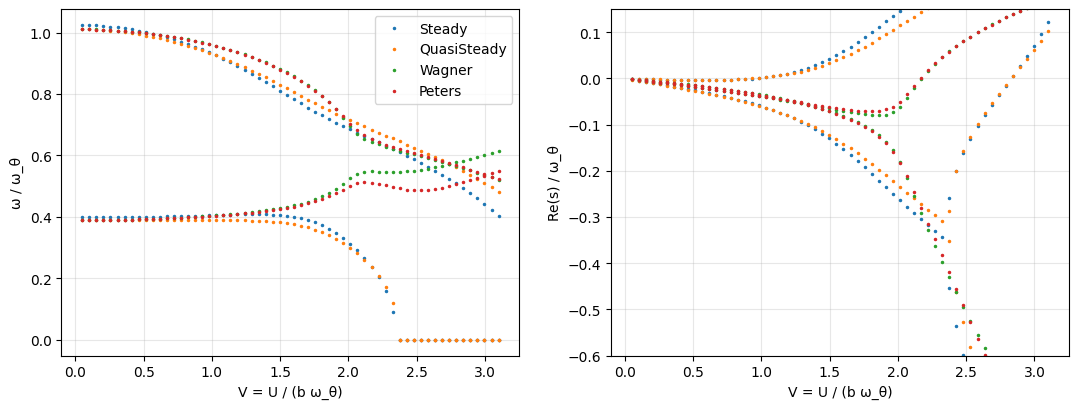

In [2]:
V = np.linspace(0.05, 3.1, 60)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for k, (name, am) in enumerate(models.items()):
    model = sec.section_model(am)
    sw = coupled.eigen_sweep(model, lambda v: p0.replace(U=v), V)
    lam = sw.eigvals[:, -4:] if am.n_states else sw.eigvals  # the 4 structural roots are the highest-|ω| ones
    for j in range(lam.shape[1]):
        osc = lam[:, j].imag >= -1e-9
        axs[0].plot(V[osc], lam[osc, j].imag, ".", color=f"C{k}", ms=3, label=name if j == 0 else None)
        axs[1].plot(V[osc], lam[osc, j].real, ".", color=f"C{k}", ms=3)
axs[0].set_ylabel("ω / ω_θ"); axs[1].set_ylabel("Re(s) / ω_θ"); axs[1].set_ylim(-0.6, 0.15)
for ax in axs: ax.set_xlabel("V = U / (b ω_θ)"); ax.grid(alpha=.3)
axs[0].legend();

In [3]:
V_exact, w_exact = sec.theodorsen_flutter(p0, (2.17, 0.65))
print(f"{'model':<12s} {'V_flutter':>10s} {'ω_f/ω_θ':>9s} {'V_div':>8s}")
for name, am in models.items():
    model = sec.section_model(am)
    Vf, s = sec.flutter_reduced_velocity(model, p0, 0.05, 3.5, 30)
    Vd = sec.divergence_reduced_velocity(model, p0, 0.05, 3.5, 30)
    print(f"{name:<12s} {Vf:10.4f} {s.imag:9.4f} {Vd:8.4f}")
print(f"{'Theodorsen':<12s} {V_exact:10.4f} {w_exact:9.4f} {np.sqrt(0.24*20/0.6):8.4f}   (exact C(k), frequency domain)")

model         V_flutter   ω_f/ω_θ    V_div


Steady           0.9428    0.9428   2.8284


QuasiSteady      0.9376    0.9411   2.8284


Wagner           2.1704    0.6443   2.8284


Peters           2.1654    0.6545   2.8284
Theodorsen       2.1839    0.6490   2.8284   (exact C(k), frequency domain)


Wagner and Peters give V_f ≈ 2.17 ("around 2.2" in Aeroelasticity.jl), within 1 % of the exact Theodorsen
solution; steady and quasi-steady theories predict much lower flutter speeds. Divergence (V_D = √8) is identical
for all models.

## Time simulation (`section-simulation`): Peters, V = 1, h(0) = 0.5

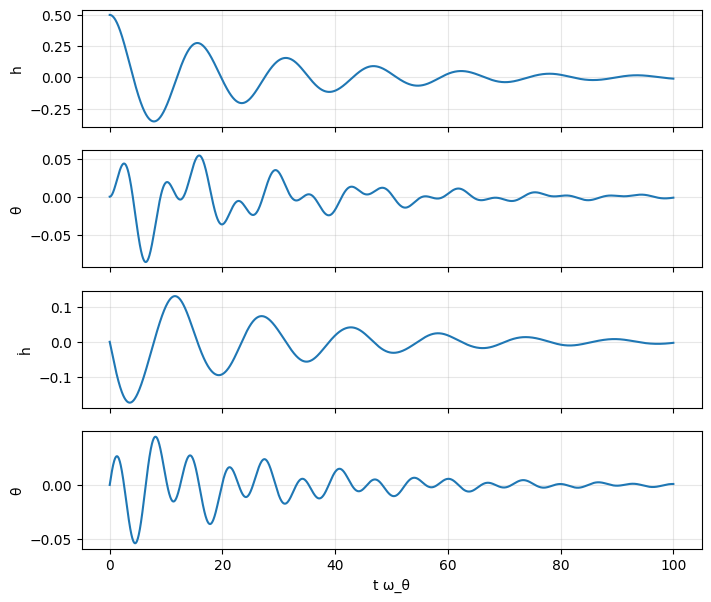

In [4]:
model = sec.section_model(sec.Peters(6))
x0 = jnp.zeros(model.n_states).at[6].set(0.5)
t, X = coupled.simulate(model, p0.replace(U=1.0), x0, t_end=100.0, dt=0.05)
fig, axs = plt.subplots(4, 1, figsize=(8, 7), sharex=True)
for ax, k, lab in zip(axs, range(6, 10), ["h", "θ", "ḣ", "θ̇"]):
    ax.plot(t, X[:, k]); ax.set_ylabel(lab); ax.grid(alpha=.3)
axs[-1].set_xlabel("t ω_θ");

## What AD adds: exact flutter sensitivities and a design map
`coupled.critical_value_gradient` differentiates the flutter point with respect to any design variable using
left/right eigenvectors and `jax.jacrev` through the coupled residual.

In [5]:
def params_fn(d, V):
    return sec.SectionParameters.from_nondimensional(a=-0.2, e=d["e"], mu=d["mu"], r2=0.24, sigma=d["sigma"], V=V)

d = {"e": -0.1, "mu": 20.0, "sigma": 0.4}
Vf, s = coupled.critical_value(model, lambda v: params_fn(d, v), 1.5, 3.0, 16)
g, gw = coupled.critical_value_gradient(model, params_fn, d, Vf, s)
print(f"V_f = {Vf:.5f}")
for k in d:
    print(f"  dV_f/d{k:<6s} = {float(g[k]): .5f}    dω_f/d{k} = {float(gw[k]): .5f}")

V_f = 2.16542
  dV_f/de      = -2.79138    dω_f/de =  0.21239
  dV_f/dmu     =  0.04713    dω_f/dmu = -0.00166
  dV_f/dsigma  = -1.34042    dω_f/dsigma =  0.53668


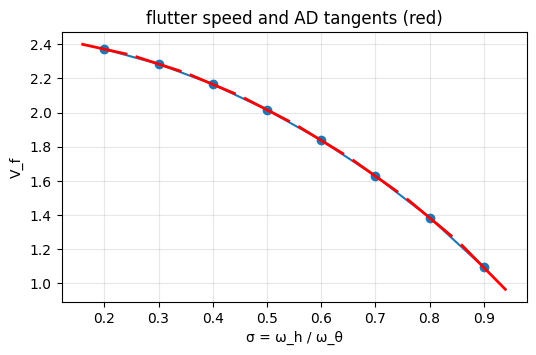

In [6]:
sigmas = np.linspace(0.2, 0.9, 8)  # for σ ≳ 1 flutter drops to very low speeds
vfs, slopes = [], []
for sg in sigmas:
    dd = dict(d, sigma=sg)
    Vf_, s_ = coupled.critical_value(model, lambda v: params_fn(dd, v), 0.3, 4.0, 30)
    vfs.append(Vf_); slopes.append(float(coupled.critical_value_gradient(model, params_fn, dd, Vf_, s_)[0]["sigma"]))
plt.figure(figsize=(6, 3.5)); plt.plot(sigmas, vfs, "o-")
for sg, vf, sl in zip(sigmas, vfs, slopes):
    plt.plot([sg - 0.04, sg + 0.04], [vf - 0.04 * sl, vf + 0.04 * sl], "r-", lw=2)
plt.xlabel("σ = ω_h / ω_θ"); plt.ylabel("V_f"); plt.title("flutter speed and AD tangents (red)"); plt.grid(alpha=.3);